In [1]:
# CÉLULA 1 — IMPORTS E CONFIGURAÇÃO GERAL
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import uaibot as ub
from cvxopt import solvers
import time

# ===== RTDE =====
import rtde_control
import rtde_receive

solvers.options["show_progress"] = False
DEBUG_QP = True
DEBUG_OBS = False
PRINT_EVERY = 250
PRINT_DEBUG_OBS = False

RUN_MODE = "simulation"   # "simulation" ou "real"
ROBOT_IP = "192.168.10.03"
USE_REAL_ROBOT = (RUN_MODE.lower() == "real")
ROBOT_2_STATIONARY = False   # True: Robô 2 estático; False: Robô 2 ativo

CONTROL_FREQUENCY = 100.0
dt = 1.0 / CONTROL_FREQUENCY

RUN_SIM_ANIMATION = True
ANIMATION_STEP = 1

# Visualização das Primitivas de Colisão dos Robôs (UaiBot)
SHOW_COLLISION_PRIMITIVES = True
ROBOT_MESH_OPACITY = 0.20 if SHOW_COLLISION_PRIMITIVES else 1.0

param_h_dist_ctrl = 1e-6
param_eps_dist_ctrl = 1e-6
param_tol_dist_ctrl = 1e-4
param_no_iter_max_dist_ctrl = 50

param_h_dist_plot = 0.0
param_eps_dist_plot = 0.0
param_tol_dist_plot = 1e-4
param_no_iter_max_dist_plot = 50

param_iter_max = 3000
param_tol_error = 0.001

param_k = 0.20
param_lambda_dls = 0.08

param_eta = 0.25
param_eta_auto = 0.02
param_eta_obs = 0.001
param_eta_rob = 0.02          # Ganho da CBF entre Robô 1 e Robô 2

param_joint_delta = 5 * np.pi / 180

param_auto_delta = 0.005
param_auto_activation = 0.02

param_obs_delta = 0.012
param_obs_activation = 0.02
param_obs_contact_tol = 1e-6
param_max_dist_obs = 0.04

# Parâmetros de segurança Robô 1 <-> Robô 2
param_rob_delta = 0.015
param_rob_activation = 0.05
param_max_dist_rob = 0.15

MAX_VEL_MODULO = np.array(
    [np.pi, np.pi, np.pi, 2*np.pi, 2*np.pi, 2*np.pi],
    dtype=float
).reshape(-1, 1)

ACC_DEFAULT = 1.0

In [2]:
# CÉLULA 2 — RTDE
# =========================================================

rtde_c = None
rtde_r = None


def connect_robot(robot_ip: str):
    global rtde_c, rtde_r
    try:
        rtde_c = rtde_control.RTDEControlInterface(robot_ip, CONTROL_FREQUENCY)
        rtde_r = rtde_receive.RTDEReceiveInterface(robot_ip, CONTROL_FREQUENCY)
    except Exception as e:
        rtde_c = None
        rtde_r = None
        raise RuntimeError(f"Falha ao conectar ao robô ({robot_ip}): {e}")


def disconnect_robot():
    global rtde_c, rtde_r

    if rtde_c is not None:
        try:
            rtde_c.speedStop()
        except Exception:
            pass
        try:
            rtde_c.disconnect()
        except Exception:
            pass

    if rtde_r is not None:
        try:
            rtde_r.disconnect()
        except Exception:
            pass

    rtde_c = None
    rtde_r = None


def read_joint_position() -> np.ndarray:
    if rtde_r is None:
        raise RuntimeError("RTDEReceiveInterface não está conectado.")
    return np.array(rtde_r.getActualQ(), dtype=float).reshape(-1, 1)


def send_joint_speed(u: np.ndarray, dt_cmd: float):
    if rtde_c is None:
        raise RuntimeError("RTDEControlInterface não está conectado.")
    u_cmd = np.asarray(u, dtype=float).reshape(-1).tolist()
    rtde_c.speedJ(u_cmd, ACC_DEFAULT, dt_cmd)

def send_joint_position(q: np.ndarray, dt_cmd: float):
    if rtde_c is None:
        raise RuntimeError("RTDEControlInterface não está conectado.")
    q_cmd = np.asarray(q, dtype=float).reshape(-1).tolist()
    rtde_c.moveJ(q_cmd, ACC_DEFAULT, dt_cmd)

In [3]:
# CÉLULA 3 — FUNÇÕES AUXILIARES (CORRIGIDA)
# =========================================================

def fun_G(_r, _param_k):
    r = np.asarray(_r, dtype=float).reshape(-1, 1)
    return -_param_k * np.sign(r) * np.sqrt(np.abs(r))


def sanitize_joint_limits(joint_limit):
    jl = np.asarray(joint_limit, dtype=float).copy()
    for j in range(jl.shape[0]):
        if not np.isfinite(jl[j, 0]):
            jl[j, 0] = -1e6
        if not np.isfinite(jl[j, 1]):
            jl[j, 1] = 1e6
    return jl


def get_link_indices_from_dist_struct(dist_struct):
    if hasattr(dist_struct, "_list_info"):
        return [int(item.link_number) for item in dist_struct._list_info]
    return None


def should_ignore_obs_constraint(obstacle, link_idx, ignored_link_for_table=0, ignored_obs_names=None):
    if ignored_obs_names and obstacle.name in ignored_obs_names:
        return True
    # Ignora mesa_1 ou mesa_2 contra a base (link 0) do respectivo robô
    if obstacle.name.startswith("mesa") and link_idx == ignored_link_for_table:
        return True
    return False


def extract_robot_col_objects(_robot, _q):
    """
    Atualiza a pose (HTM) dos objetos de colisão do robô para a configuração _q
    usando apenas a cinemática direta (fkm), SEM apagar os frames de animação!
    """
    htm_dh = _robot.fkm(q=_q, axis="dh")
    col_objs = []

    for link_idx, link in enumerate(_robot.links):
        htm_link = htm_dh[link_idx]
        for sub_idx, col_item in enumerate(link.col_objects):
            obj_3d = col_item[0]
            htm_local = col_item[1]
            # Posiciona o objeto de colisão no espaço sem alterar a animação do robô
            obj_3d._htm = htm_link @ htm_local
            col_objs.append((link_idx, sub_idx, obj_3d))

    return col_objs


def compute_min_self_distance_euclidean(_robot, _q):
    ds_auto_plot = _robot.compute_dist_auto(
        q=_q,
        h=param_h_dist_plot,
        eps=param_eps_dist_plot,
        tol=param_tol_dist_plot,
        no_iter_max=param_no_iter_max_dist_plot
    )

    dist_auto_plot = np.asarray(ds_auto_plot.dist_vect, dtype=float).reshape(-1)

    if dist_auto_plot.size == 0:
        return np.inf

    return float(np.min(dist_auto_plot))


def compute_min_obs_distance_euclidean(
    _robot,
    _q,
    _all_obstacles,
    ignored_link_for_table=0
):
    min_obs_dist_eucl = np.inf

    for obstacle in _all_obstacles:
        ds_obs_plot = _robot.compute_dist(
            q=_q,
            obj=obstacle,
            h=param_h_dist_plot,
            eps=param_eps_dist_plot,
            tol=param_tol_dist_plot,
            no_iter_max=param_no_iter_max_dist_plot,
            max_dist=param_max_dist_obs
        )

        dist_obs_plot = np.asarray(ds_obs_plot.dist_vect, dtype=float).reshape(-1)

        if dist_obs_plot.size == 0:
            continue

        link_idx_list = get_link_indices_from_dist_struct(ds_obs_plot)

        for k in range(dist_obs_plot.shape[0]):
            d_k = float(dist_obs_plot[k])

            link_idx = None
            if link_idx_list is not None and k < len(link_idx_list):
                link_idx = int(link_idx_list[k])

            if should_ignore_obs_constraint(
                obstacle=obstacle,
                link_idx=link_idx,
                ignored_link_for_table=ignored_link_for_table
            ):
                continue

            min_obs_dist_eucl = min(min_obs_dist_eucl, d_k)

    return min_obs_dist_eucl


def compute_min_rob_to_rob_distance_euclidean(_robot1, _q1, _robot2, _q2):
    min_rob_dist_eucl = np.inf
    col_objs_2 = extract_robot_col_objects(_robot2, _q2)

    for _, _, obj_2 in col_objs_2:
        ds_plot = _robot1.compute_dist(
            q=_q1,
            obj=obj_2,
            h=param_h_dist_plot,
            eps=param_eps_dist_plot,
            tol=param_tol_dist_plot,
            no_iter_max=param_no_iter_max_dist_plot,
            max_dist=param_max_dist_rob
        )
        dist_vect = np.asarray(ds_plot.dist_vect, dtype=float).reshape(-1)
        if dist_vect.size > 0:
            min_rob_dist_eucl = min(min_rob_dist_eucl, float(np.min(dist_vect)))

    return min_rob_dist_eucl


In [4]:
# CÉLULA 4 — CONTROLE DIFERENCIAL
# =========================================================

def compute_u_nominal(_robot, _q, _htm_tg, _lambda_dls):
    _q = np.asarray(_q, dtype=float).reshape(-1, 1)

    r, jac_r = _robot.task_function(q=_q, htm_tg=_htm_tg)

    r = np.asarray(r, dtype=float).reshape(-1, 1)
    jac_r = np.asarray(jac_r, dtype=float)

    if jac_r.ndim == 1:
        jac_r = jac_r.reshape(1, -1)

    G = fun_G(r, param_k)

    JJt = jac_r @ jac_r.T

    u_nominal = jac_r.T @ np.linalg.inv(
        JJt + (_lambda_dls ** 2) * np.eye(JJt.shape[0])
    ) @ G

    u_nominal = np.asarray(u_nominal, dtype=float).reshape(-1, 1)

    error_r = float(param_k * np.sum(np.abs(r) ** (3/2)))

    return u_nominal, error_r, r, jac_r

In [5]:
# CÉLULA 5 — FILTRO DE RESTRIÇÕES COM TEMPOS (12 JUNTAS)
# =========================================================

def _build_single_robot_constraints(
    _robot,
    _q,
    _all_obstacles,
    col_offset,
    total_joints,
    robot_label,
    ignored_link_for_table=0,
    ignored_obs_names=None
):
    """
    Monta os blocos de restrições individuais de um robô (limites de junta,
    velocidade, autocolisão e obstáculos estáticos) posicionados em
    col_offset : col_offset + no_joint dentro da matriz de 12 colunas.
    """
    _q = np.asarray(_q, dtype=float).reshape(-1, 1)
    no_joint = np.shape(_robot.q)[0]
    joint_limits = sanitize_joint_limits(_robot.joint_limit)

    A_list = []
    b_list = []
    debug_rows = []

    def pad_cols(mat_local):
        mat_full = np.zeros((mat_local.shape[0], total_joints), dtype=float)
        mat_full[:, col_offset:col_offset + no_joint] = mat_local
        return mat_full

    # 1. LIMITES ARTICULARES
    A1 = pad_cols(np.eye(no_joint))
    b1 = -param_eta * (_q - joint_limits[:, [0]] - param_joint_delta)

    A2 = pad_cols(-np.eye(no_joint))
    b2 = -param_eta * (joint_limits[:, [1]] - _q - param_joint_delta)

    A_list.extend([A1, A2])
    b_list.extend([b1, b2])

    if DEBUG_QP:
        for j in range(no_joint):
            debug_rows.append((f"{robot_label}_joint_lower", j, float(b1[j, 0])))
            debug_rows.append((f"{robot_label}_joint_upper", j, float(b2[j, 0])))

    # 2. LIMITES DE VELOCIDADE
    A3 = pad_cols(np.eye(no_joint))
    b3 = -MAX_VEL_MODULO

    A4 = pad_cols(-np.eye(no_joint))
    b4 = -MAX_VEL_MODULO

    A_list.extend([A3, A4])
    b_list.extend([b3, b4])

    if DEBUG_QP:
        for j in range(no_joint):
            debug_rows.append((f"{robot_label}_vel_lower", j, float(b3[j, 0])))
            debug_rows.append((f"{robot_label}_vel_upper", j, float(b4[j, 0])))

    # 3. AUTOCOLISÃO
    min_self_dist_ctrl = np.inf
    n_self_constraints = 0

    t0 = time.perf_counter()
    ds_auto = _robot.compute_dist_auto(
        q=_q,
        h=param_h_dist_ctrl,
        eps=param_eps_dist_ctrl,
        tol=param_tol_dist_ctrl,
        no_iter_max=param_no_iter_max_dist_ctrl
    )
    time_self_dist = time.perf_counter() - t0

    jac_auto = np.asarray(ds_auto.jac_dist_mat, dtype=float)
    dist_auto = np.asarray(ds_auto.dist_vect, dtype=float).reshape(-1, 1)

    if jac_auto.ndim == 1 and jac_auto.size > 0:
        jac_auto = jac_auto.reshape(1, -1)
    if jac_auto.size > 0 and jac_auto.shape[1] != no_joint:
        jac_auto = jac_auto.reshape(-1, no_joint)

    if dist_auto.size > 0:
        min_self_dist_ctrl = float(np.min(dist_auto))

    for k in range(dist_auto.shape[0]):
        d_k = float(dist_auto[k, 0])
        if d_k <= param_auto_activation:
            rhs = -param_eta_auto * (d_k - param_auto_delta)
            A_list.append(pad_cols(jac_auto[k:k+1, :]))
            b_list.append(np.array([[rhs]], dtype=float))
            if DEBUG_QP:
                debug_rows.append((f"{robot_label}_self", k, d_k, rhs))
            n_self_constraints += 1

    # 4. OBSTÁCULOS EXTERNOS
    min_obs_dist_ctrl = np.inf
    n_obs_constraints = 0
    time_obs_dist_total = 0.0
    time_obs_dist_by_obj = {}

    for obstacle in _all_obstacles:
        if ignored_obs_names and obstacle.name in ignored_obs_names:
            continue
        t0 = time.perf_counter()
        ds_obs = _robot.compute_dist(
            q=_q,
            obj=obstacle,
            h=param_h_dist_ctrl,
            eps=param_eps_dist_ctrl,
            tol=param_tol_dist_ctrl,
            no_iter_max=param_no_iter_max_dist_ctrl,
            max_dist=param_max_dist_obs
        )
        dt_obs = time.perf_counter() - t0
        time_obs_dist_total += dt_obs
        time_obs_dist_by_obj[obstacle.name] = time_obs_dist_by_obj.get(obstacle.name, 0.0) + dt_obs

        jac_obs = np.asarray(ds_obs.jac_dist_mat, dtype=float)
        dist_obs = np.asarray(ds_obs.dist_vect, dtype=float).reshape(-1, 1)

        if jac_obs.ndim == 1 and jac_obs.size > 0:
            jac_obs = jac_obs.reshape(1, -1)
        if jac_obs.size > 0 and jac_obs.shape[1] != no_joint:
            jac_obs = jac_obs.reshape(-1, no_joint)

        link_idx_list = get_link_indices_from_dist_struct(ds_obs)

        for k in range(dist_obs.shape[0]):
            d_k = float(dist_obs[k, 0])
            link_idx = None
            if link_idx_list is not None and k < len(link_idx_list):
                link_idx = int(link_idx_list[k])

            ignored = should_ignore_obs_constraint(
                obstacle=obstacle,
                link_idx=link_idx,
                ignored_link_for_table=ignored_link_for_table,
                ignored_obs_names=ignored_obs_names
            )

            if ignored:
                continue

            min_obs_dist_ctrl = min(min_obs_dist_ctrl, d_k)

            if d_k <= param_obs_activation and d_k > param_obs_contact_tol:
                rhs = -param_eta_obs * (d_k - param_obs_delta)
                A_list.append(pad_cols(jac_obs[k:k+1, :]))
                b_list.append(np.array([[rhs]], dtype=float))
                if DEBUG_QP:
                    debug_rows.append((f"{robot_label}_obs", obstacle.name, k, link_idx, d_k, rhs))
                n_obs_constraints += 1

    A_rob = np.vstack(A_list) if len(A_list) > 0 else np.zeros((0, total_joints), dtype=float)
    b_rob = np.vstack(b_list) if len(b_list) > 0 else np.zeros((0, 1), dtype=float)

    return (
        A_rob,
        b_rob,
        debug_rows,
        min_self_dist_ctrl,
        n_self_constraints,
        min_obs_dist_ctrl,
        n_obs_constraints,
        time_self_dist,
        time_obs_dist_total,
        time_obs_dist_by_obj
    )


def apply_constraints_dual(
    _robot1,
    _q1,
    _u_nom1,
    _robot2,
    _q2,
    _u_nom2,
    _all_obstacles,
    ignored_link_for_table=0,
    ignored_obs_names_r1=None,
    ignored_obs_names_r2=None,
    robot2_stationary=False,
    allow_tool_handover=False
):
    t_apply_ini = time.perf_counter()

    _q1 = np.asarray(_q1, dtype=float).reshape(-1, 1)
    _q2 = np.asarray(_q2, dtype=float).reshape(-1, 1)
    _u_nom1 = np.asarray(_u_nom1, dtype=float).reshape(-1, 1)
    _u_nom2 = np.asarray(_u_nom2, dtype=float).reshape(-1, 1)
    if robot2_stationary:
        _u_nom2 = np.zeros_like(_u_nom2)

    n1 = _q1.shape[0]
    n2 = _q2.shape[0]
    total_joints = n1 + n2  # 12 juntas

    # -----------------------------------------------------
    # 1 a 4. RESTRIÇÕES DO ROBÔ 1 (Colunas 0 a 5) e ROBÔ 2 (Colunas 6 a 11)
    # -----------------------------------------------------
    (
        A_r1, b_r1, dbg_r1,
        min_self_1, n_self_1,
        min_obs_1, n_obs_1,
        t_self_1, t_obs_1, t_obs_obj_1
    ) = _build_single_robot_constraints(
        _robot=_robot1,
        _q=_q1,
        _all_obstacles=_all_obstacles,
        col_offset=0,
        total_joints=total_joints,
        robot_label="R1",
        ignored_link_for_table=ignored_link_for_table,
        ignored_obs_names=ignored_obs_names_r1
    )

    (
        A_r2, b_r2, dbg_r2,
        min_self_2, n_self_2,
        min_obs_2, n_obs_2,
        t_self_2, t_obs_2, t_obs_obj_2
    ) = _build_single_robot_constraints(
        _robot=_robot2,
        _q=_q2,
        _all_obstacles=_all_obstacles,
        col_offset=n1,
        total_joints=total_joints,
        robot_label="R2",
        ignored_link_for_table=ignored_link_for_table,
        ignored_obs_names=ignored_obs_names_r2
    )

    A_list = [A_r1, A_r2]
    b_list = [b_r1, b_r2]
    debug_rows = dbg_r1 + dbg_r2

    # -----------------------------------------------------
    # 5. COLISÃO ENTRE ROBÔ 1 E ROBÔ 2 (Acoplamento 12 juntas)
    # d_dot = J_r1 * u_1 + J_r2 * u_2 >= -eta_rob * (d - delta_rob)
    # -----------------------------------------------------
    t0_rob = time.perf_counter()
    min_rob_dist_ctrl = np.inf
    n_rob_constraints = 0

    col_objs_r1 = extract_robot_col_objects(_robot1, _q1)
    col_objs_r2 = extract_robot_col_objects(_robot2, _q2)

    # 5a. Jacobiano do Robô 1 em relação aos objetos de colisão do Robô 2
    jac_r1_map = {}
    dist_r1_map = {}

    for link2_idx, sub2_idx, obj2 in col_objs_r2:
        ds_12 = _robot1.compute_dist(
            q=_q1,
            obj=obj2,
            h=param_h_dist_ctrl,
            eps=param_eps_dist_ctrl,
            tol=param_tol_dist_ctrl,
            no_iter_max=param_no_iter_max_dist_ctrl,
            max_dist=param_max_dist_rob
        )
        jac_12 = np.asarray(ds_12.jac_dist_mat, dtype=float)
        dist_12 = np.asarray(ds_12.dist_vect, dtype=float).reshape(-1, 1)

        if jac_12.ndim == 1 and jac_12.size > 0:
            jac_12 = jac_12.reshape(1, -1)
        if jac_12.size > 0 and jac_12.shape[1] != n1:
            jac_12 = jac_12.reshape(-1, n1)

        if hasattr(ds_12, "_list_info"):
            for k, item in enumerate(ds_12._list_info):
                key = (int(item.link_number), int(getattr(item, "link_col_obj_number", getattr(item, "obj_col_number", 0))), link2_idx, sub2_idx)
                d_val = float(dist_12[k, 0])
                if allow_tool_handover and (int(item.link_number) == 5 and link2_idx == 5):
                    continue
                min_rob_dist_ctrl = min(min_rob_dist_ctrl, d_val)
                if d_val <= param_rob_activation:
                    jac_r1_map[key] = jac_12[k:k+1, :]
                    dist_r1_map[key] = d_val

    # 5b. Jacobiano do Robô 2 em relação aos objetos de colisão do Robô 1 (apenas se houver pares próximos e Robô 2 ativo)
    jac_r2_map = {}
    if not robot2_stationary and len(jac_r1_map) > 0:
        active_r1_subobjs = {(k[0], k[1]) for k in jac_r1_map.keys()}
        for link1_idx, sub1_idx, obj1 in col_objs_r1:
            if (link1_idx, sub1_idx) not in active_r1_subobjs:
                continue
            ds_21 = _robot2.compute_dist(
                q=_q2,
                obj=obj1,
                h=param_h_dist_ctrl,
                eps=param_eps_dist_ctrl,
                tol=param_tol_dist_ctrl,
                no_iter_max=param_no_iter_max_dist_ctrl,
                max_dist=param_max_dist_rob
            )
            jac_21 = np.asarray(ds_21.jac_dist_mat, dtype=float)
            if jac_21.ndim == 1 and jac_21.size > 0:
                jac_21 = jac_21.reshape(1, -1)
            if jac_21.size > 0 and jac_21.shape[1] != n2:
                jac_21 = jac_21.reshape(-1, n2)

            if hasattr(ds_21, "_list_info"):
                for k, item in enumerate(ds_21._list_info):
                    key = (link1_idx, sub1_idx, int(item.link_number), int(getattr(item, "link_col_obj_number", getattr(item, "obj_col_number", 0))))
                    jac_r2_map[key] = jac_21[k:k+1, :]

    # Monta a linha acoplada [J_r1, J_r2] de 12 colunas
    for key, j1_row in jac_r1_map.items():
        d_val = dist_r1_map[key]
        j2_row = jac_r2_map.get(key, np.zeros((1, n2), dtype=float))

        row_12 = np.hstack((j1_row, j2_row))
        rhs = -param_eta_rob * (d_val - param_rob_delta)

        A_list.append(row_12)
        b_list.append(np.array([[rhs]], dtype=float))
        n_rob_constraints += 1

        if DEBUG_QP:
            debug_rows.append(("rob1_rob2", key, d_val, rhs))

    time_rob_dist = time.perf_counter() - t0_rob

    # -----------------------------------------------------
    # RESOLUÇÃO DO QP DE 12 JUNTAS
    # -----------------------------------------------------
    A = np.vstack(A_list)
    b = np.vstack(b_list)

    u_nominal_12 = np.vstack((_u_nom1, _u_nom2))
    H = 2.0 * np.eye(total_joints)
    f = -2.0 * u_nominal_12

    if robot2_stationary:
        A_eq = np.hstack((np.zeros((n2, n1)), np.eye(n2)))
        b_eq = np.zeros((n2, 1))
    else:
        A_eq = None
        b_eq = None

    try:
        t0_qp = time.perf_counter()
        u_12 = ub.Utils.solve_qp(
            np.matrix(H),
            np.matrix(f),
            np.matrix(A),
            np.matrix(b),
            np.matrix(A_eq) if A_eq is not None else None,
            np.matrix(b_eq) if b_eq is not None else None
        )
        time_qp = time.perf_counter() - t0_qp
    except Exception as e:
        if DEBUG_QP:
            print("\n[DEBUG] QP de 12 juntas inviável")
            print(f"min_self_1 = {min_self_1:.6f} | min_self_2 = {min_self_2:.6f}")
            print(f"min_obs_1  = {min_obs_1:.6f} | min_obs_2  = {min_obs_2:.6f}")
            print(f"min_rob12  = {min_rob_dist_ctrl:.6f}")
            print(f"n_rob_constraints = {n_rob_constraints}")
        raise e

    if u_12 is None:
        raise RuntimeError("solve_qp retornou None.")

    u_12 = np.asarray(u_12, dtype=float).reshape(-1, 1)
    if np.any(~np.isfinite(u_12)):
        raise RuntimeError("Solução do QP inválida.")

    u1 = u_12[0:n1, :]
    u2 = u_12[n1:total_joints, :]
    if robot2_stationary:
        u2 = np.zeros_like(u2)

    # Consolidação de métricas e tempos
    min_self_dist_ctrl = min(min_self_1, min_self_2)
    n_self_constraints = n_self_1 + n_self_2
    min_obs_dist_ctrl = min(min_obs_1, min_obs_2)
    n_obs_constraints = n_obs_1 + n_obs_2

    time_self_dist = t_self_1 + t_self_2
    time_obs_dist_total = t_obs_1 + t_obs_2

    time_obs_dist_by_obj = dict(t_obs_obj_1)
    for k_obj, v_time in t_obs_obj_2.items():
        time_obs_dist_by_obj[k_obj] = time_obs_dist_by_obj.get(k_obj, 0.0) + v_time
    time_obs_dist_by_obj["robo1_vs_robo2"] = time_rob_dist

    time_apply_constraints = time.perf_counter() - t_apply_ini

    return (
        u1,
        u2,
        min_self_dist_ctrl,
        n_self_constraints,
        min_obs_dist_ctrl,
        n_obs_constraints,
        min_rob_dist_ctrl,
        n_rob_constraints,
        time_self_dist,
        time_obs_dist_total,
        time_rob_dist,
        time_obs_dist_by_obj,
        time_qp,
        time_apply_constraints
    )


In [6]:
# CÉLULA 6 — CENÁRIO / MODELO DIGITAL (2 BANCADAS + 2 UR3e)
# =========================================================

h_mesa = 0.81
w_mesa_orig, d_mesa_orig = 0.655, 1.0

# Distância Y entre as duas bancadas/robôs: 0.66 m
# (Como cada UR3e tem 0.50 m de alcance, a soma é 1.00 m > 0.66 m,
# garantindo uma zona de colisão/interseção de ~0.34 m entre os dois robôs)
DY_BANCADA_2 = -0.66


def criar_bancada(sufixo, dy):
    htm_m = ub.Utils.trn([(0.66 - 0.25) / 2, dy, h_mesa / 2])
    mesa_b = ub.Box(
        htm=htm_m,
        width=d_mesa_orig,
        depth=w_mesa_orig,
        height=h_mesa,
        name=f"mesa_{sufixo}",
        color="white",
        opacity=1.0
    )

    x_rampa, y_rampa = 0.2745, -0.1775 + dy
    largura_rampa = 0.055
    altura_rampa = 0.114
    base_rampa = 0.185
    hipotenusa = 0.213
    theta_rampa = np.arctan2(altura_rampa, base_rampa)

    htm_rampa = ub.Utils.trn([x_rampa, y_rampa, h_mesa]) @ ub.Utils.rotx(-theta_rampa)
    rampa_b = ub.Box(
        htm=htm_rampa,
        width=largura_rampa,
        depth=hipotenusa,
        height=altura_rampa,
        name=f"rampa_solida_{sufixo}",
        color="#228B22",
        opacity=1.0
    )

    x_s1, y_s1 = -0.153, 0.0 + dy
    r_s1, h_s1 = 0.03, 0.014
    base_s1_b = ub.Cylinder(
        htm=ub.Utils.trn([x_s1, y_s1, h_mesa + h_s1 / 2]),
        radius=r_s1,
        height=h_s1,
        name=f"base_s1_{sufixo}",
        color="black",
        opacity=1.0
    )
    topo_s1_b = ub.Ball(
        htm=ub.Utils.trn([x_s1, y_s1, h_mesa + h_s1]),
        radius=r_s1,
        name=f"topo_s1_{sufixo}",
        color="gray",
        opacity=1.0
    )

    x_s2, y_s2 = -0.15, 0.169 + dy
    r_base_s2, h_base_s2 = 0.014, 0.007
    r_pino_s2, h_pino_s2 = 0.008, 0.03
    base_s2_b = ub.Cylinder(
        htm=ub.Utils.trn([x_s2, y_s2, h_mesa + h_base_s2 / 2]),
        radius=r_base_s2,
        height=h_base_s2,
        name=f"base_s2_{sufixo}",
        color="#404040",
        opacity=1.0
    )
    pino_s2_b = ub.Cylinder(
        htm=ub.Utils.trn([x_s2, y_s2, h_mesa + h_base_s2 + h_pino_s2 / 2]),
        radius=r_pino_s2,
        height=h_pino_s2,
        name=f"pino_s2_{sufixo}",
        color="blue",
        opacity=1.0
    )

    # Caixa removida da bancada conforme solicitado
    # L_caixa, C_caixa, H_caixa = 0.35, 0.25, 0.20
    # x_caixa, y_caixa, z_caixa = 0.3, 0.14 + dy, h_mesa + H_caixa / 2
    # caixa_b = ub.Box(
    #     htm=ub.Utils.trn([x_caixa, y_caixa, z_caixa]),
    #     width=L_caixa,
    #     depth=C_caixa,
    #     height=H_caixa,
    #     name=f"caixa_{sufixo}",
    #     color="#8B4513",
    #     opacity=0.85
    # )

    return [mesa_b, rampa_b, base_s1_b, topo_s1_b, base_s2_b, pino_s2_b]


# Objetos das Bancadas 1 e 2
bancada_1_objs = criar_bancada("1", dy=0.0)
bancada_2_objs = criar_bancada("2", dy=DY_BANCADA_2)

# Gaiola externa englobando as duas bancadas (sem parede divisória entre elas)
z_gaiola = h_mesa + 0.5
y_parede_esq = 0.285 + 0.05
y_parede_dir = DY_BANCADA_2 - 0.285 - 0.08
y_centro_gaiola = (y_parede_esq + y_parede_dir) / 2.0
depth_gaiola_dupla = y_parede_esq - y_parede_dir

obs = [
    ub.Box(
        htm=ub.Utils.trn([-0.25 - 0.01, y_centro_gaiola, z_gaiola]),
        width=0.02,
        depth=depth_gaiola_dupla,
        height=1.0,
        name="parede_tras",
        color="red",
        opacity=0.3
    ),
    ub.Box(
        htm=ub.Utils.trn([0.66 + 0.01, y_centro_gaiola, z_gaiola]),
        width=0.02,
        depth=depth_gaiola_dupla,
        height=1.0,
        name="parede_frente",
        color="red",
        opacity=0.3
    ),
    ub.Box(
        htm=ub.Utils.trn([0.205, y_parede_esq, z_gaiola]),
        width=0.91,
        depth=0.02,
        height=1.0,
        name="parede_esq_ext",
        color="blue",
        opacity=0.3
    ),
    ub.Box(
        htm=ub.Utils.trn([0.205, y_parede_dir, z_gaiola]),
        width=0.91,
        depth=0.02,
        height=1.0,
        name="parede_dir_ext",
        color="blue",
        opacity=0.3
    )
]

# Robô 1 (Bancada 1 em y = 0.0) e Robô 2 (Bancada 2 em y = -0.66)
robot = ub.Robot.create_ur_ur3e(
    htm=ub.Utils.trn([0, 0, h_mesa]) @ ub.Utils.rotz(-3*np.pi/4),
    name="robot_1",
    opacity=ROBOT_MESH_OPACITY
)

robot_2 = ub.Robot.create_ur_ur3e(
    htm=ub.Utils.trn([0, DY_BANCADA_2, h_mesa]) @ ub.Utils.rotz(-3*np.pi/4),
    name="robot_2",
    opacity=ROBOT_MESH_OPACITY
)

# Pose inicial confortável do Robô 1 (com cotovelo dobrado a 90° em vez de esticado em vela)
q0_1 = np.array([
    3*np.pi/4, -np.pi/2, -np.pi/2, -np.pi/2, np.pi/2, 0
], dtype=float).reshape(-1, 1)

# Pose inicial confortável do Robô 2 (com cotovelo dobrado a 90°)
q0_2 = np.array([
    3*np.pi/4, -np.pi/2, -np.pi/2, -np.pi/2, np.pi/2, 0
], dtype=float).reshape(-1, 1)

# Poses iniciais nos robôs para animação t=0
robot.add_ani_frame(time=0, q=q0_1)
robot_2.add_ani_frame(time=0, q=q0_2)

# Caixa a ser manipulada pelo Robô 1 na bancada 1
w_cx, d_cx, h_cx = 0.04, 0.04, 0.12
x_cx, y_cx, z_cx = 0.35, 0.15, h_mesa + h_cx / 2
caixa_pegar = ub.Box(
    htm=ub.Utils.trn([x_cx, y_cx, z_cx]),
    width=w_cx,
    depth=d_cx,
    height=h_cx,
    name="caixa_pegar",
    color="#D2691E",
    opacity=0.9
)

# Alvos da tarefa do Robô 1 (Pegar a caixa na bancada 1 e transportar até o ponto intermediário):
# 1. Ponto de Home (posição de espera confortável recuada na bancada com efetuador voltado para baixo)
htm_tg_1_0 = ub.Utils.trn([0.25, 0.05, h_mesa + 0.30]) @ ub.Utils.rotx(np.pi)

# 2. Ponto de Pega (centro geométrico da caixa: descida em -z até [x_cx, y_cx, z_cx])
htm_tg_1_1 = ub.Utils.trn([x_cx, y_cx, z_cx]) @ ub.Utils.rotx(np.pi)

# 3. Ponto intermediário entre as duas bancadas (y = -0.33)
#    A caixa é incorporada ao modelo de colisão do Robô 1 e transportada.
htm_tg_1_2 = ub.Utils.trn([0.25, -0.33, h_mesa + 0.20]) @ ub.Utils.rotx(np.pi)

# 4. Ponto de recuo pós-entrega do Robô 1
htm_tg_1_3 = ub.Utils.trn([0.25, -0.33, h_mesa + 0.35]) @ ub.Utils.rotx(np.pi)

htm_tg = [htm_tg_1_0, htm_tg_1_1, htm_tg_1_2, htm_tg_1_3]
htm_tg_1 = htm_tg

# Alvos do Robô 2 (Transferência cooperativa):
# 1. Home recuado na bancada 2
htm_tg_2_0 = ub.Utils.trn([0.25, 0.05 + DY_BANCADA_2, h_mesa + 0.30]) @ ub.Utils.rotx(-np.pi/2)
# 2. Pega perpendicular da peça no ponto intermediário (permanece segurando a peça)
htm_tg_2_1 = ub.Utils.trn([0.25, -0.33, h_mesa + 0.20]) @ ub.Utils.rotx(-np.pi/2)
htm_tg_2 = [htm_tg_2_0, htm_tg_2_1]

# Poses iniciais dos efetuadores para posicionar o rastro em t=0
_, htm_eef_1_init = robot.jac_geo(q=q0_1)
_, htm_eef_2_init = robot_2.jac_geo(q=q0_2)

# Elementos visuais Robô 1
target_ball = ub.Ball(htm=htm_tg[0], radius=0.02, name="alvo_1", color="purple")
ball_tr = ub.Ball(htm=htm_eef_1_init, radius=0.01, name="rastro_1", color="cyan")
frame_pose = ub.Frame(htm=htm_tg[0], size=0.1)

# Elementos visuais Robô 2
target_ball_2 = ub.Ball(htm=htm_tg_2[0], radius=0.02, name="alvo_2", color="orange", opacity=0.3 if ROBOT_2_STATIONARY else 1.0)
ball_tr_2 = ub.Ball(htm=htm_eef_2_init, radius=0.01, name="rastro_2", color="magenta", opacity=0.3 if ROBOT_2_STATIONARY else 1.0)
frame_pose_2 = ub.Frame(htm=htm_tg_2[0], size=0.1)

all_obstacles = bancada_1_objs + bancada_2_objs + obs + [caixa_pegar]

sim = ub.Simulation(
    [
        robot, robot_2,
        target_ball, target_ball_2,
        ball_tr, ball_tr_2,
        frame_pose, frame_pose_2
    ] + all_obstacles
)

# Adiciona primitivas de colisão à simulação para visualização gráfica
if SHOW_COLLISION_PRIMITIVES:
    robot.add_col_object(sim)
    robot_2.add_col_object(sim)

if USE_REAL_ROBOT:
    connect_robot(ROBOT_IP)
    send_joint_position(q0_1, dt_cmd=0.1)
    disconnect_robot()


In [7]:
# CÉLULA 7 — LOOP PRINCIPAL (2 ROBÔS / 12 JUNTAS)
# =========================================================

mode_1 = 0
mode_2 = 0
iter_start_1 = 0
iter_start_2 = 0

cont = True
i = 0

n_targets_1 = len(htm_tg)
n_targets_2 = 1 if ROBOT_2_STATIONARY else len(htm_tg_2)
max_iter_per_target = param_iter_max // n_targets_1 if ROBOT_2_STATIONARY else param_iter_max // max(n_targets_1, n_targets_2)

# Controle de estado para manipulação da caixa
ignored_obs_r1 = set()
ignored_obs_r2 = {"caixa_pegar"}
caixa_incorporada = False
caixa_transferida_r2 = False
r1_chegou_intermediario = False
allow_tool_handover = False
htm_rel_eef2_to_box = None
htm_rel_eef_to_box = None

hist_q = []       # Guardará o vetor de 12 juntas [q1; q2]
hist_q1 = []
hist_q2 = []
hist_u = []       # Guardará o vetor de 12 velocidades [u1; u2]
hist_u_nom = []   # Guardará o vetor de 12 velocidades nominais
hist_t = []
hist_e = []       # Soma dos erros de tarefa (Robô 1 + Robô 2)
hist_e1 = []
hist_e2 = []
hist_p1 = []
hist_p2 = []

hist_self_ctrl = []
hist_obs_ctrl = []
hist_rob_ctrl = []

hist_nself = []
hist_nobs = []
hist_nrob = []

hist_target = []

hist_time_self_dist = []
hist_time_obs_dist_total = []
hist_time_rob_dist = []
hist_time_obs_dist_by_obj = []
hist_time_qp = []
hist_time_apply_constraints = []

if USE_REAL_ROBOT:
    connect_robot(ROBOT_IP)

try:
    if USE_REAL_ROBOT:
        q1 = read_joint_position()
    else:
        q1 = q0_1.copy()

    q2 = q0_2.copy()

    while cont:
        i += 1
        cont = i < param_iter_max

        iter_local_1 = i - iter_start_1
        iter_local_2 = i - iter_start_2

        htm_target_current_1 = htm_tg[min(mode_1, n_targets_1 - 1)]
        htm_target_current_2 = htm_tg_2[min(mode_2, n_targets_2 - 1)]

        frame_pose.add_ani_frame(time=i * dt, htm=htm_target_current_1)
        frame_pose_2.add_ani_frame(time=i * dt, htm=htm_target_current_2)

        try:
            # Controle nominal Robô 1 (6 juntas)
            u_nom1, error_r1, r1, jac_r1 = compute_u_nominal(
                _robot=robot,
                _q=q1,
                _htm_tg=htm_target_current_1,
                _lambda_dls=param_lambda_dls
            )

            # Controle nominal Robô 2 (6 juntas)
            if ROBOT_2_STATIONARY:
                u_nom2 = np.zeros((6, 1))
                error_r2 = 0.0
                r2 = np.zeros((6, 1))
                jac_r2 = np.zeros((6, 6))
            else:
                u_nom2, error_r2, r2, jac_r2 = compute_u_nominal(
                    _robot=robot_2,
                    _q=q2,
                    _htm_tg=htm_target_current_2,
                    _lambda_dls=param_lambda_dls
                )

            # Filtro QP conjunto para as 12 juntas
            (
                u1,
                u2,
                min_self_dist_ctrl,
                n_self_constraints,
                min_obs_dist_ctrl,
                n_obs_constraints,
                min_rob_dist_ctrl,
                n_rob_constraints,
                time_self_dist,
                time_obs_dist_total,
                time_rob_dist,
                time_obs_dist_by_obj,
                time_qp,
                time_apply_constraints
            ) = apply_constraints_dual(
                _robot1=robot,
                _q1=q1,
                _u_nom1=u_nom1,
                _robot2=robot_2,
                _q2=q2,
                _u_nom2=u_nom2,
                _all_obstacles=all_obstacles,
                ignored_link_for_table=0,
                ignored_obs_names_r1=ignored_obs_r1,
                ignored_obs_names_r2=ignored_obs_r2,
                robot2_stationary=ROBOT_2_STATIONARY,
                allow_tool_handover=allow_tool_handover
            )

        except Exception as e:
            print(f"Erro na iteração {i}: {type(e).__name__}: {e}")
            break

        error_total = error_r1 + error_r2

        if i % PRINT_EVERY == 0 or i == 1:
            lbl_r2 = "PARADO" if ROBOT_2_STATIONARY else f"{mode_2+1}"
            print(
                f"Iter {i:04d} | "
                f"Alvos=({mode_1+1},{lbl_r2}) | "
                f"e1={error_r1:.4f} e2={error_r2:.4f} | "
                f"self={min_self_dist_ctrl:.4f} | "
                f"obs={min_obs_dist_ctrl:.4f} | "
                f"rob12={min_rob_dist_ctrl:.4f} | "
                f"n_rob12={n_rob_constraints}"
            )

        # Transição de alvos Robô 1
        if mode_1 < n_targets_1:
            if mode_1 == 2 and error_r1 <= param_tol_error:
                if not r1_chegou_intermediario:
                    print(">>> Robô 1 chegou ao ponto intermediário e aguarda o Robô 2 para a entrega!")
                    r1_chegou_intermediario = True

            can_advance_r1 = (error_r1 <= param_tol_error) or (iter_local_1 >= max_iter_per_target)
            if mode_1 == 2 and not caixa_transferida_r2:
                can_advance_r1 = False

            if can_advance_r1:
                print(f"Robô 1: Fase {mode_1} concluída (erro={error_r1:.5f}) -> Avançando...")
                mode_1 += 1
                iter_start_1 = i

                # Transição Fase 0 -> 1: Chegou no ponto de Home;
                # Desconsidera a caixa como obstáculo para permitir descida no sentido oposto à normal até a pega
                if mode_1 == 1:
                    print(">>> Robô 1 atingiu ponto de Home! Desconsiderando caixa como obstáculo para descida de pega.")
                    ignored_obs_r1.add("caixa_pegar")

                # Transição Fase 1 -> 2: Chegou na pose de pega;
                # Incorpora a caixa ao modelo de colisão do Robô 1 e calcula acoplamento
                elif mode_1 == 2:
                    print(">>> Robô 1 realizou a pega da caixa! Incorporando ao modelo de colisão do Robô 1.")
                    caixa_incorporada = True
                    htm_dh_r1 = robot.fkm(q=q1, axis="dh")
                    htm_link5 = htm_dh_r1[5]
                    htm_caixa_atual = ub.Utils.trn([x_cx, y_cx, z_cx])
                    htm_local_link5 = np.linalg.inv(htm_link5) @ htm_caixa_atual
                    caixa_col_attached = ub.Box(
                        width=w_cx, depth=d_cx, height=h_cx,
                        name="caixa_acoplada_r1", color="#D2691E"
                    )
                    robot.links[5].col_objects.append([caixa_col_attached, htm_local_link5])

                    _, htm_eef_grasp = robot.jac_geo(q=q1)
                    htm_rel_eef_to_box = np.linalg.inv(htm_eef_grasp) @ htm_caixa_atual

                if mode_1 < n_targets_1:
                    target_ball.add_ani_frame(time=i * dt, htm=htm_tg[mode_1])

        # Transição de alvos Robô 2
        if not ROBOT_2_STATIONARY and mode_2 < n_targets_2:
            tol_r2 = 0.0001 if mode_2 == 1 else param_tol_error
            can_advance_r2 = (error_r2 <= tol_r2) or (iter_local_2 >= max_iter_per_target)
            if mode_2 == 0 and not r1_chegou_intermediario:
                can_advance_r2 = False

            if can_advance_r2:
                print(f"Robô 2: Fase {mode_2} concluída (erro={error_r2:.5f}) -> Avançando...")
                mode_2 += 1
                iter_start_2 = i

                if mode_2 == 1:
                    print(">>> Robô 2 aproximando-se para pega perpendicular da peça!")
                    allow_tool_handover = True

                elif mode_2 == 2:
                    print(">>> Robô 2 realizou a pega perpendicular da peça! Transferindo caixa para o Robô 2.")
                    caixa_transferida_r2 = True
                    for idx_c, itm in enumerate(list(robot.links[5].col_objects)):
                        if itm[0].name == "caixa_acoplada_r1":
                            robot.links[5].col_objects.pop(idx_c)
                            break

                    htm_dh_r2 = robot_2.fkm(q=q2, axis="dh")
                    htm_link5_r2 = htm_dh_r2[5]
                    htm_cx_handover = ub.Utils.trn([0.25, -0.33, h_mesa + 0.20])
                    htm_local_link5_r2 = np.linalg.inv(htm_link5_r2) @ htm_cx_handover
                    caixa_col_attached_r2 = ub.Box(
                        width=w_cx, depth=d_cx, height=h_cx,
                        name="caixa_acoplada_r2", color="#D2691E"
                    )
                    robot_2.links[5].col_objects.append([caixa_col_attached_r2, htm_local_link5_r2])

                    _, htm_eef_2_grasp = robot_2.jac_geo(q=q2)
                    htm_rel_eef2_to_box = np.linalg.inv(htm_eef_2_grasp) @ htm_cx_handover

                if mode_2 < n_targets_2:
                    target_ball_2.add_ani_frame(time=i * dt, htm=htm_tg_2[mode_2])

        if ROBOT_2_STATIONARY:
            if mode_1 >= n_targets_1:
                cont = False
                break
        else:
            if mode_1 >= n_targets_1 and mode_2 >= n_targets_2:
                cont = False
                break

        # Integração / Envio de velocidade
        if USE_REAL_ROBOT:
            send_joint_speed(u1, dt)
            q1 = read_joint_position()
        else:
            q1 = q1 + u1 * dt

        if ROBOT_2_STATIONARY:
            u2 = np.zeros((6, 1))
            q2 = q0_2.copy()
        else:
            q2 = q2 + u2 * dt

        _, htm_eef_1 = robot.jac_geo(q=q1)
        p_eef_1 = np.array(htm_eef_1[0:3, 3]).reshape(3)

        _, htm_eef_2 = robot_2.jac_geo(q=q2)
        p_eef_2 = np.array(htm_eef_2[0:3, 3]).reshape(3)

        hist_q1.append(np.asarray(q1, dtype=float).copy())
        hist_q2.append(np.asarray(q2, dtype=float).copy())
        hist_q.append(np.vstack((q1, q2)))
        hist_u.append(np.vstack((u1, u2)))
        hist_u_nom.append(np.vstack((u_nom1, u_nom2)))

        hist_t.append(i * dt)
        hist_e1.append(float(error_r1))
        hist_e2.append(float(error_r2))
        hist_e.append(float(error_total))
        hist_p1.append(p_eef_1.copy())
        hist_p2.append(p_eef_2.copy())

        hist_self_ctrl.append(min_self_dist_ctrl)
        hist_obs_ctrl.append(min_obs_dist_ctrl)
        hist_rob_ctrl.append(min_rob_dist_ctrl)

        hist_nself.append(n_self_constraints)
        hist_nobs.append(n_obs_constraints)
        hist_nrob.append(n_rob_constraints)

        hist_target.append((mode_1, mode_2))

        hist_time_self_dist.append(time_self_dist)
        hist_time_obs_dist_total.append(time_obs_dist_total)
        hist_time_rob_dist.append(time_rob_dist)
        hist_time_obs_dist_by_obj.append(time_obs_dist_by_obj)
        hist_time_qp.append(time_qp)
        hist_time_apply_constraints.append(time_apply_constraints)

        if RUN_SIM_ANIMATION and (i % ANIMATION_STEP == 0):
            robot.add_ani_frame(time=i * dt, q=q1)
            robot_2.add_ani_frame(time=i * dt, q=q2)
            ball_tr.add_ani_frame(time=i * dt, htm=ub.Utils.trn(p_eef_1))
            ball_tr_2.add_ani_frame(time=i * dt, htm=ub.Utils.trn(p_eef_2))

            # Atualização da pose da caixa (estática, transportada por R1 ou por R2)
            if caixa_transferida_r2 and htm_rel_eef2_to_box is not None:
                htm_cx_visual = htm_eef_2 @ htm_rel_eef2_to_box
                caixa_pegar.add_ani_frame(time=i * dt, htm=htm_cx_visual)
            elif caixa_incorporada and htm_rel_eef_to_box is not None:
                htm_cx_visual = htm_eef_1 @ htm_rel_eef_to_box
                caixa_pegar.add_ani_frame(time=i * dt, htm=htm_cx_visual)
            else:
                caixa_pegar.add_ani_frame(time=i * dt, htm=ub.Utils.trn([x_cx, y_cx, z_cx]))

finally:
    if USE_REAL_ROBOT:
        disconnect_robot()


Iter 0001 | Alvos=(1,1) | e1=0.4364 e2=0.6364 | self=0.0110 | obs=0.0061 | rob12=inf | n_rob12=0
Iter 0250 | Alvos=(1,1) | e1=0.1740 e2=0.2706 | self=0.0107 | obs=0.0560 | rob12=inf | n_rob12=0
Iter 0500 | Alvos=(1,1) | e1=0.0509 e2=0.0915 | self=0.0105 | obs=0.0491 | rob12=inf | n_rob12=0
Iter 0750 | Alvos=(1,1) | e1=0.0072 e2=0.0168 | self=0.0107 | obs=0.0455 | rob12=inf | n_rob12=0
Robô 1: Fase 0 concluída (erro=0.00721) -> Avançando...
>>> Robô 1 atingiu ponto de Home! Desconsiderando caixa como obstáculo para descida de pega.
Iter 1000 | Alvos=(2,1) | e1=0.0048 e2=0.0042 | self=0.0114 | obs=0.0560 | rob12=inf | n_rob12=0
Robô 1: Fase 1 concluída (erro=0.00100) -> Avançando...
>>> Robô 1 realizou a pega da caixa! Incorporando ao modelo de colisão do Robô 1.
Iter 1250 | Alvos=(3,1) | e1=0.0538 e2=0.0035 | self=0.0112 | obs=0.0560 | rob12=inf | n_rob12=0
Iter 1500 | Alvos=(3,1) | e1=0.0132 e2=0.0028 | self=0.0121 | obs=inf | rob12=inf | n_rob12=0
Iter 1750 | Alvos=(3,1) | e1=0.0019 e

In [ ]:
# CÉLULA 8 — FINALIZAÇÃO
# =========================================================

if RUN_SIM_ANIMATION:
    sim.run()

hist_self_eucl = []
hist_obs_eucl = []
hist_rob_eucl = []

for q1_k, q2_k in zip(hist_q1, hist_q2):
    d_self_1 = compute_min_self_distance_euclidean(robot, q1_k)
    d_self_2 = compute_min_self_distance_euclidean(robot_2, q2_k)
    hist_self_eucl.append(min(d_self_1, d_self_2))

    d_obs_1 = compute_min_obs_distance_euclidean(robot, q1_k, all_obstacles, ignored_link_for_table=0)
    d_obs_2 = compute_min_obs_distance_euclidean(robot_2, q2_k, all_obstacles, ignored_link_for_table=0)
    hist_obs_eucl.append(min(d_obs_1, d_obs_2))

    d_rob_12 = compute_min_rob_to_rob_distance_euclidean(robot, q1_k, robot_2, q2_k)
    hist_rob_eucl.append(d_rob_12)

print("\nExecução finalizada.")
print(f"Número de iterações: {len(hist_t)}")

if len(hist_e) > 0:
    print(f"Erro final de tarefa (R1 + R2): {hist_e[-1]:.6f} (R1={hist_e1[-1]:.6f}, R2={hist_e2[-1]:.6f})")

if len(hist_self_ctrl) > 0:
    print(f"Menor distância de autocolisão (controlador): {np.min(hist_self_ctrl):.6f} m")

if len(hist_obs_ctrl) > 0:
    print(f"Menor distância a obstáculos (controlador): {np.min(hist_obs_ctrl):.6f} m")

if len(hist_rob_ctrl) > 0:
    print(f"Menor distância entre Robô 1 e Robô 2 (controlador): {np.min(hist_rob_ctrl):.6f} m")

if len(hist_self_eucl) > 0:
    print(f"Menor distância de autocolisão (euclidiana): {np.min(hist_self_eucl):.6f} m")

if len(hist_obs_eucl) > 0:
    print(f"Menor distância a obstáculos (euclidiana): {np.min(hist_obs_eucl):.6f} m")

if len(hist_rob_eucl) > 0:
    print(f"Menor distância entre Robô 1 e Robô 2 (euclidiana): {np.min(hist_rob_eucl):.6f} m")

In [ ]:
# CÉLULA 9 — TEMPOS COMPUTACIONAIS
# =========================================================

def print_time_stats(name, values):
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        print(f"{name}: sem dados")
        return

    print(
        f"{name}: "
        f"média = {np.mean(values)*1000:.4f} ms | "
        f"desvio padrão = {np.std(values)*1000:.4f} ms | "
        f"mín = {np.min(values)*1000:.4f} ms | "
        f"máx = {np.max(values)*1000:.4f} ms"
    )


print("\n================ TEMPOS COMPUTACIONAIS (12 JUNTAS) ================")

print_time_stats("Distância de autocolisão (R1 + R2)", hist_time_self_dist)
print_time_stats("Distância total dos obstáculos (R1 + R2)", hist_time_obs_dist_total)
print_time_stats("Distância mútua Robô 1 <-> Robô 2", hist_time_rob_dist)
print_time_stats("Programação quadrática QP (12 variáveis)", hist_time_qp)
print_time_stats("Filtro completo de restrições", hist_time_apply_constraints)

all_obj_names = sorted(
    set(
        name
        for item in hist_time_obs_dist_by_obj
        for name in item.keys()
    )
)

print("\n--------- Tempo de distância por obstáculo / par ---------")

for obj_name in all_obj_names:
    values = [item[obj_name] for item in hist_time_obs_dist_by_obj if obj_name in item]
    print_time_stats(f"Distância objeto: {obj_name}", values)


================ TEMPOS COMPUTACIONAIS (12 JUNTAS) ================
Distância de autocolisão (R1 + R2): média = 9.3097 ms | desvio padrão = 6.2028 ms | mín = 5.4177 ms | máx = 204.1174 ms
Distância total dos obstáculos (R1 + R2): média = 3.8419 ms | desvio padrão = 0.5655 ms | mín = 2.4492 ms | máx = 24.1966 ms
Distância mútua Robô 1 <-> Robô 2: média = 4.2837 ms | desvio padrão = 1.6674 ms | mín = 1.9675 ms | máx = 10.0253 ms
Programação quadrática QP (12 variáveis): média = 0.3243 ms | desvio padrão = 0.0381 ms | mín = 0.2099 ms | máx = 0.8627 ms
Filtro completo de restrições: média = 19.9231 ms | desvio padrão = 6.6153 ms | mín = 11.9397 ms | máx = 215.2689 ms

--------- Tempo de distância por obstáculo / par ---------
Distância objeto: base_s1_1: média = 0.2646 ms | desvio padrão = 0.0848 ms | mín = 0.1378 ms | máx = 3.9878 ms
Distância objeto: base_s1_2: média = 0.2313 ms | desvio padrão = 0.1281 ms | mín = 0.1240 ms | máx = 6.7775 ms
Distância objeto: base_s2_1: média = 0.2061 m

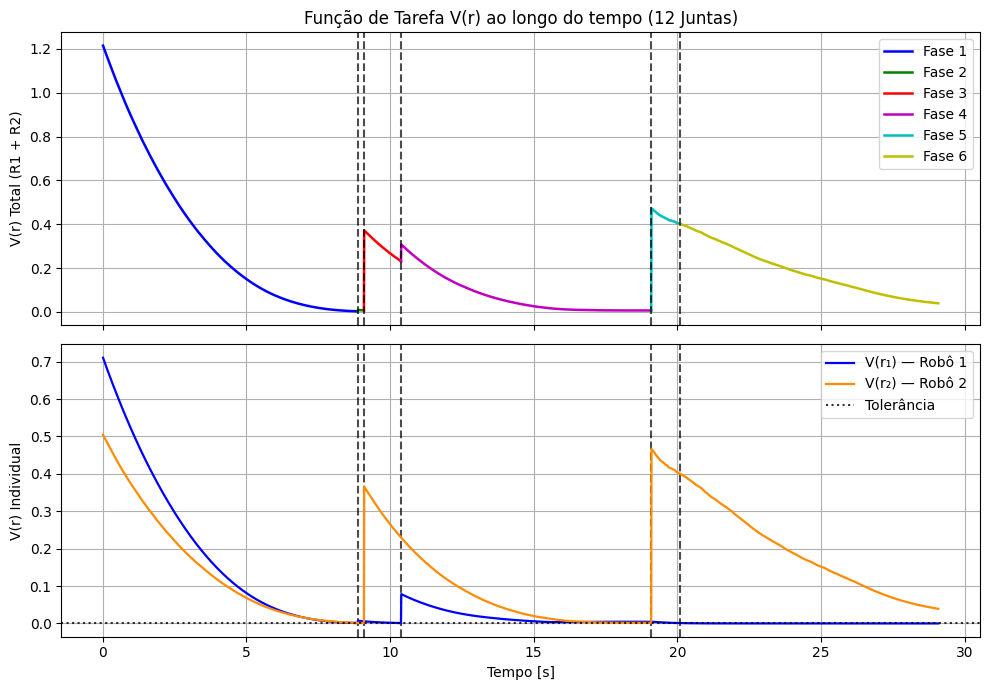

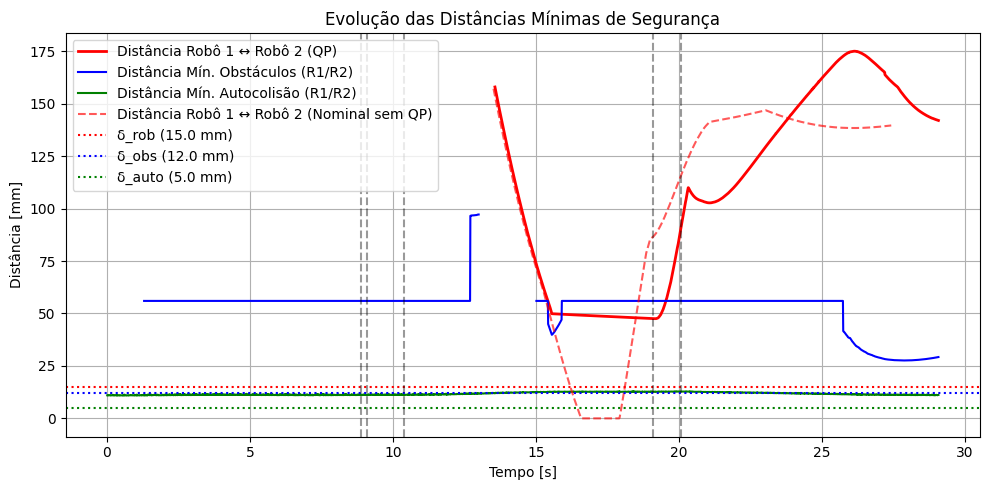

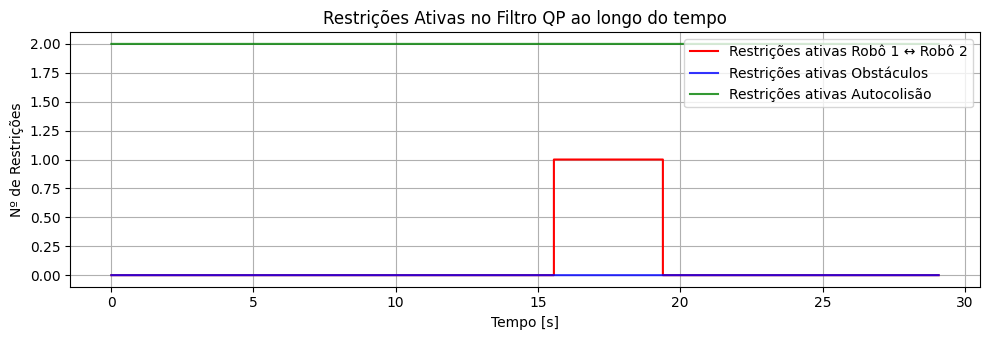

In [ ]:
# CÉLULA 10 — GRÁFICOS (V(r) E DISTÂNCIAS PARA 2 ROBÔS)
# =========================================================

hist_t_np = np.asarray(hist_t, dtype=float)
hist_e_np = np.asarray(hist_e, dtype=float)
hist_e1_np = np.asarray(hist_e1, dtype=float)
hist_e2_np = np.asarray(hist_e2, dtype=float)

hist_self_ctrl_np = np.asarray(hist_self_ctrl, dtype=float)
hist_obs_ctrl_np = np.asarray(hist_obs_ctrl, dtype=float)
hist_rob_ctrl_np = np.asarray(hist_rob_ctrl, dtype=float)

# Detecta automaticamente os índices onde qualquer um dos robôs trocou de alvo
peaks = [
    k for k in range(1, len(hist_target))
    if hist_target[k] != hist_target[k - 1]
]

# ---------------------------------------------------------
# GRÁFICO 1: V(r) por segmentos (mantendo o estilo original)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

colors_seg = ['b', 'g', 'r', 'm', 'c', 'y']
idx_bounds = [0] + peaks + [len(hist_t_np)]

for s in range(len(idx_bounds) - 1):
    i_ini = idx_bounds[s]
    # Inclui +1 ponto para não deixar buraco visual entre os segmentos
    i_fim = min(idx_bounds[s + 1] + 1, len(hist_t_np))
    cor = colors_seg[s % len(colors_seg)]

    axes[0].plot(
        hist_t_np[i_ini:i_fim],
        hist_e_np[i_ini:i_fim],
        color=cor,
        linewidth=1.8,
        label=f"Fase {s+1}" if i_fim > i_ini else None
    )

for p in peaks:
    axes[0].axvline(hist_t_np[p], linestyle='--', color='k', alpha=0.7)
    axes[1].axvline(hist_t_np[p], linestyle='--', color='k', alpha=0.7)

axes[0].set_ylabel("V(r) Total (R1 + R2)")
axes[0].set_title("Função de Tarefa V(r) ao longo do tempo (12 Juntas)")
axes[0].grid(True)
axes[0].legend(loc="upper right")

# Subplot individual: Robô 1 vs Robô 2
axes[1].plot(hist_t_np, hist_e1_np, 'b-', linewidth=1.6, label="V(r₁) — Robô 1")
axes[1].plot(hist_t_np, hist_e2_np, 'darkorange', linewidth=1.6, label="V(r₂) — Robô 2 (Parado)" if ROBOT_2_STATIONARY else "V(r₂) — Robô 2")
axes[1].axhline(param_tol_error, linestyle=':', color='k', alpha=0.8, label="Tolerância")
axes[1].set_xlabel("Tempo [s]")
axes[1].set_ylabel("V(r) Individual")
axes[1].grid(True)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICO 2: Distâncias de Segurança (Autocolisão, Obstáculos e Robô 1 <-> Robô 2)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(hist_t_np, hist_rob_ctrl_np * 1000, 'r-', linewidth=2.0, label="Distância Robô 1 ↔ Robô 2 (QP)")
plt.plot(hist_t_np, hist_obs_ctrl_np * 1000, 'b-', linewidth=1.5, label="Distância Mín. Obstáculos (R1/R2)")
plt.plot(hist_t_np, hist_self_ctrl_np * 1000, 'g-', linewidth=1.5, label="Distância Mín. Autocolisão (R1/R2)")

# Se a Célula 12 (nominal) já tiver sido rodada, plota a curva sem filtro para comparação
if "hist_rob_eucl_nominal" in globals() and len(hist_rob_eucl_nominal) > 0:
    t_nom_np = np.asarray(hist_t_nominal, dtype=float)
    rob_nom_np = np.asarray(hist_rob_eucl_nominal, dtype=float)
    plt.plot(
        t_nom_np,
        rob_nom_np * 1000,
        'r--',
        alpha=0.65,
        linewidth=1.5,
        label="Distância Robô 1 ↔ Robô 2 (Nominal sem QP)"
    )

plt.axhline(param_rob_delta * 1000, color='r', linestyle=':', label=f"δ_rob ({param_rob_delta*1000:.1f} mm)")
plt.axhline(param_obs_delta * 1000, color='b', linestyle=':', label=f"δ_obs ({param_obs_delta*1000:.1f} mm)")
plt.axhline(param_auto_delta * 1000, color='g', linestyle=':', label=f"δ_auto ({param_auto_delta*1000:.1f} mm)")

for p in peaks:
    plt.axvline(hist_t_np[p], linestyle='--', color='k', alpha=0.4)

plt.xlabel("Tempo [s]")
plt.ylabel("Distância [mm]")
plt.title("Evolução das Distâncias Mínimas de Segurança")
plt.grid(True)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICO 3: Número de restrições ativas no QP (12 Juntas)
# ---------------------------------------------------------
plt.figure(figsize=(10, 3.5))
plt.step(hist_t_np, hist_nrob, 'r-', where='post', label="Restrições ativas Robô 1 ↔ Robô 2")
plt.step(hist_t_np, hist_nobs, 'b-', where='post', alpha=0.8, label="Restrições ativas Obstáculos")
plt.step(hist_t_np, hist_nself, 'g-', where='post', alpha=0.8, label="Restrições ativas Autocolisão")
plt.xlabel("Tempo [s]")
plt.ylabel("Nº de Restrições")
plt.title("Restrições Ativas no Filtro QP ao longo do tempo")
plt.grid(True)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

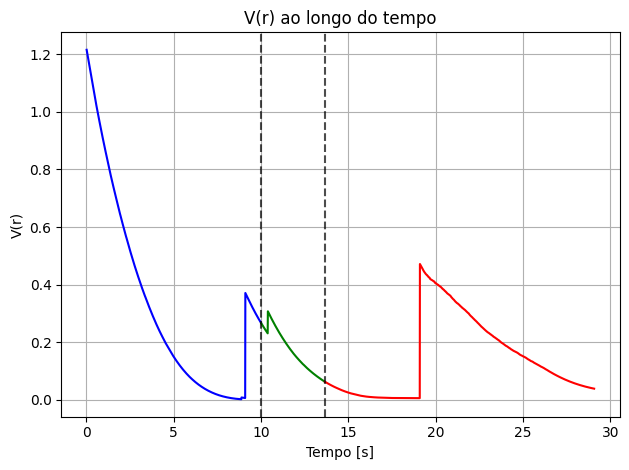

In [ ]:
# exemplo: substitua pelos índices reais
peaks = [1000, 1365]
# segmentos
plt.plot(hist_t_np[:peaks[0]], hist_e_np[:peaks[0]], 'b')
plt.plot(hist_t_np[peaks[0]:peaks[1]], hist_e_np[peaks[0]:peaks[1]], 'g')
plt.plot(hist_t_np[peaks[1]:], hist_e_np[peaks[1]:], 'r')

# linhas verticais
for p in peaks:
    plt.axvline(hist_t_np[p], linestyle='--', color='k', alpha=0.7)

plt.xlabel("Tempo [s]")
plt.ylabel("V(r)")
plt.title("V(r) ao longo do tempo")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
sim.save("/home/gabriel/Mestrado/")

In [ ]:
# 1. OBJETOS
box = ub.Box(
    htm=ub.Utils.trn([0.3, 0.0, 0.2]),
    width=0.2, depth=0.2, height=0.2
)

cylinder = ub.Cylinder(
    htm=ub.Utils.trn([0.6, 0.1, 0.2]),
    radius=0.05, height=0.2
)

# 2. DISTÂNCIA
point_box, point_cyl, distance, hist_error = box.compute_dist(
    obj=cylinder,
    p_init=None,        # escolha inicial do ponto (opcional)
    tol=1e-4,           # critério de convergência
    no_iter_max=50,     # nº máx. de iterações
    h=1e-6,             # >0 → distância diferenciável
    eps=1e-6,           # >0 → suavização adicional
    mode='auto'         # 'c++' recomendado p/ diferenciável
)


# 3. INTERPRETAÇÃO
"""
RETORNOS:
point_box  → ponto mais próximo na caixa
point_cyl  → ponto mais próximo no cilindro
distance   → distância mínima
hist_error → convergência do algoritmo (GAP)

TIPOS DE DISTÂNCIA:
- Euclidiana: h=0, eps=0 (rápida, não diferenciável)
- Diferenciável: h>0 ou eps>0 (suave, usada em controle)

USO EM CONTROLE:
A versão diferenciável permite calcular:
    d_dot = J_dist * q_dot

Essencial para QP, CBF e controle com restrições.
"""

'\nRETORNOS:\npoint_box  → ponto mais próximo na caixa\npoint_cyl  → ponto mais próximo no cilindro\ndistance   → distância mínima\nhist_error → convergência do algoritmo (GAP)\n\nTIPOS DE DISTÂNCIA:\n- Euclidiana: h=0, eps=0 (rápida, não diferenciável)\n- Diferenciável: h>0 ou eps>0 (suave, usada em controle)\n\nUSO EM CONTROLE:\nA versão diferenciável permite calcular:\n    d_dot = J_dist * q_dot\n\nEssencial para QP, CBF e controle com restrições.\n'

In [ ]:
# CÉLULA EXTRA — SIMULAÇÃO SEM RESTRIÇÕES (2 ROBÔS / 12 JUNTAS)
# Controle diferencial puro para visualizar trajetória nominal e colisão
# =========================================================

RUN_MODE_TMP = "simulation"

htm_tg_1_nom = list(htm_tg)
htm_tg_2_nom = list(htm_tg_2)

# Instancia robôs dedicados para não sobrescrever a simulação com QP
robot_nom_1 = ub.Robot.create_ur_ur3e(
    htm=ub.Utils.trn([0, 0, h_mesa]) @ ub.Utils.rotz(-3*np.pi/4),
    name="robot_nom_1",
    opacity=ROBOT_MESH_OPACITY
)
robot_nom_2 = ub.Robot.create_ur_ur3e(
    htm=ub.Utils.trn([0, DY_BANCADA_2, h_mesa]) @ ub.Utils.rotz(-3*np.pi/4),
    name="robot_nom_2",
    opacity=ROBOT_MESH_OPACITY
)

robot_nom_1.add_ani_frame(time=0, q=q0_1)
robot_nom_2.add_ani_frame(time=0, q=q0_2)

# Elementos visuais nominais — Robô 1
target_ball_nom_1 = ub.Ball(
    htm=htm_tg_1_nom[0],
    radius=0.025,
    color="purple",
    name="alvo_nominal_1"
)
ball_tr_nom_1 = ub.Ball(
    htm=np.identity(4),
    radius=0.008,
    color="cyan",
    name="rastro_nominal_1"
)
frame_pose_nom_1 = ub.Frame(htm=htm_tg_1_nom[0], size=0.1)

# Elementos visuais nominais — Robô 2
target_ball_nom_2 = ub.Ball(
    htm=htm_tg_2_nom[0],
    radius=0.025,
    color="orange",
    name="alvo_nominal_2"
)
ball_tr_nom_2 = ub.Ball(
    htm=np.identity(4),
    radius=0.008,
    color="magenta",
    name="rastro_nominal_2"
)
frame_pose_nom_2 = ub.Frame(htm=htm_tg_2_nom[0], size=0.1)

sim_nominal = ub.Simulation(
    [
        robot_nom_1, robot_nom_2,
        target_ball_nom_1, target_ball_nom_2,
        ball_tr_nom_1, ball_tr_nom_2,
        frame_pose_nom_1, frame_pose_nom_2
    ] + all_obstacles
)

# Adiciona primitivas de colisão dos robôs nominais à simulação
if SHOW_COLLISION_PRIMITIVES:
    robot_nom_1.add_col_object(sim_nominal)
    robot_nom_2.add_col_object(sim_nominal)

# Parâmetros locais da simulação nominal
q1_nom = q0_1.copy()
q2_nom = q0_2.copy()

mode_nom_1 = 0
mode_nom_2 = 0
iter_start_nom_1 = 0
iter_start_nom_2 = 0

i = 0
cont = True

param_iter_max_nominal = 3000
param_tol_error_nominal = 0.001
n_targets_nom_1 = len(htm_tg_1_nom)
n_targets_nom_2 = 1 if ROBOT_2_STATIONARY else len(htm_tg_2_nom)
max_iter_per_target_nominal = param_iter_max_nominal // n_targets_nom_1 if ROBOT_2_STATIONARY else param_iter_max_nominal // max(n_targets_nom_1, n_targets_nom_2)

hist_e_nominal = []
hist_e1_nominal = []
hist_e2_nominal = []
hist_t_nominal = []
hist_q1_nominal = []
hist_q2_nominal = []
hist_p1_nominal = []
hist_p2_nominal = []
hist_rob_eucl_nominal = []

while cont:
    i += 1
    cont = i < param_iter_max_nominal

    iter_local_1 = i - iter_start_nom_1
    iter_local_2 = i - iter_start_nom_2

    htm_curr_1 = htm_tg_1_nom[min(mode_nom_1, n_targets_nom_1 - 1)]
    htm_curr_2 = htm_tg_2_nom[min(mode_nom_2, n_targets_nom_2 - 1)]

    u_nom1, error_r1, _, _ = compute_u_nominal(
        _robot=robot_nom_1,
        _q=q1_nom,
        _htm_tg=htm_curr_1,
        _lambda_dls=param_lambda_dls
    )

    if ROBOT_2_STATIONARY:
        u_nom2 = np.zeros((6, 1))
        error_r2 = 0.0
    else:
        u_nom2, error_r2, _, _ = compute_u_nominal(
            _robot=robot_nom_2,
            _q=q2_nom,
            _htm_tg=htm_curr_2,
            _lambda_dls=param_lambda_dls
        )

    # SEM RESTRIÇÕES: aplica diretamente o controle diferencial nominal nas 12 juntas
    u1 = u_nom1.copy()
    u2 = np.zeros((6, 1)) if ROBOT_2_STATIONARY else u_nom2.copy()

    q1_nom = q1_nom + u1 * dt
    if not ROBOT_2_STATIONARY:
        q2_nom = q2_nom + u2 * dt

    _, htm_eef_1 = robot_nom_1.jac_geo(q=q1_nom)
    p_eef_1 = np.asarray(htm_eef_1[0:3, 3]).reshape(3)

    _, htm_eef_2 = robot_nom_2.jac_geo(q=q2_nom)
    p_eef_2 = np.asarray(htm_eef_2[0:3, 3]).reshape(3)

    hist_e1_nominal.append(float(error_r1))
    hist_e2_nominal.append(float(error_r2))
    hist_e_nominal.append(float(error_r1 + error_r2))
    hist_t_nominal.append(i * dt)
    hist_q1_nominal.append(q1_nom.copy())
    hist_q2_nominal.append(q2_nom.copy())
    hist_p1_nominal.append(p_eef_1.copy())
    hist_p2_nominal.append(p_eef_2.copy())

    # Distância euclidiana entre os robôs sem filtro (para comprovar a colisão)
    d_rob_nom = compute_min_rob_to_rob_distance_euclidean(
        robot_nom_1, q1_nom, robot_nom_2, q2_nom
    )
    hist_rob_eucl_nominal.append(d_rob_nom)

    robot_nom_1.add_ani_frame(time=i * dt, q=q1_nom)
    robot_nom_2.add_ani_frame(time=i * dt, q=q2_nom)
    ball_tr_nom_1.add_ani_frame(time=i * dt, htm=ub.Utils.trn(p_eef_1))
    ball_tr_nom_2.add_ani_frame(time=i * dt, htm=ub.Utils.trn(p_eef_2))
    frame_pose_nom_1.add_ani_frame(time=i * dt, htm=htm_curr_1)
    frame_pose_nom_2.add_ani_frame(time=i * dt, htm=htm_curr_2)

    # Troca de alvos Robô 1
    if mode_nom_1 < n_targets_nom_1:
        if (error_r1 <= param_tol_error_nominal) or (iter_local_1 >= max_iter_per_target_nominal):
            print(
                f"Troca de alvo nominal R1 | alvo={mode_nom_1+1}/{n_targets_nom_1} | "
                f"erro={error_r1:.5f} | timeout={iter_local_1 >= max_iter_per_target_nominal}"
            )
            mode_nom_1 += 1
            iter_start_nom_1 = i
            if mode_nom_1 < n_targets_nom_1:
                target_ball_nom_1.add_ani_frame(time=i * dt, htm=htm_tg_1_nom[mode_nom_1])

    # Troca de alvos Robô 2
    if mode_nom_2 < n_targets_nom_2:
        if (error_r2 <= param_tol_error_nominal) or (iter_local_2 >= max_iter_per_target_nominal):
            print(
                f"Troca de alvo nominal R2 | alvo={mode_nom_2+1}/{n_targets_nom_2} | "
                f"erro={error_r2:.5f} | timeout={iter_local_2 >= max_iter_per_target_nominal}"
            )
            mode_nom_2 += 1
            iter_start_nom_2 = i
            if mode_nom_2 < n_targets_nom_2:
                target_ball_nom_2.add_ani_frame(time=i * dt, htm=htm_tg_2_nom[mode_nom_2])

    if ROBOT_2_STATIONARY:
        if mode_nom_1 >= n_targets_nom_1:
            cont = False
    else:
        if mode_nom_1 >= n_targets_nom_1 and mode_nom_2 >= n_targets_nom_2:
            cont = False

print("\nSimulação nominal sem restrições (2 robôs) finalizada.")
print(f"Número de iterações: {len(hist_t_nominal)}")
print(f"Erro final total: {hist_e_nominal[-1]:.6f} (R1={hist_e1_nominal[-1]:.6f}, R2={hist_e2_nominal[-1]:.6f})")
print(f"Menor distância entre Robô 1 e Robô 2 (sem filtro): {np.min(hist_rob_eucl_nominal):.6f} m")

sim_nominal.run()

Troca de alvo nominal R1 | alvo=1/3 | erro=0.00099 | timeout=False
Troca de alvo nominal R2 | alvo=1/3 | erro=0.00099 | timeout=False
Troca de alvo nominal R1 | alvo=2/3 | erro=0.00100 | timeout=False
Troca de alvo nominal R1 | alvo=3/3 | erro=0.00099 | timeout=False
Troca de alvo nominal R2 | alvo=2/3 | erro=0.00099 | timeout=False
Troca de alvo nominal R2 | alvo=3/3 | erro=0.02389 | timeout=True

Simulação nominal sem restrições (2 robôs) finalizada.
Número de iterações: 2743
Erro final total: 0.023903 (R1=0.000010, R2=0.023894)
Menor distância entre Robô 1 e Robô 2 (sem filtro): 0.000000 m


In [ ]:
sim_nominal.save("/home/gabriel/Mestrado/", file_name="simulacao_nominal")


In [ ]:
print(robot.joint_limit)
print (robot.joint_limit[1])

[[-6.2832  6.2832]
 [-6.2832  6.2832]
 [-6.2832  6.2832]
 [-6.2832  6.2832]
 [-6.2832  6.2832]
 [   -inf     inf]]
[[-6.2832  6.2832]]
